# Titanic Survival Prediction — Model Building & Evaluation

**Author:** Junior Jele  
Guided learning project adapted from [Beginner-Data-Science-Projects](https://github.com/tkarim45/Beginner-Data-Science-Projects).
The source project's license and attribution should accompany any redistributed source material.

We compare seven classifiers, learn preprocessing from training passengers,
validate with preprocessing refitted inside each fold, tune logistic regression,
and predict an outcome for a fictional passenger.

**Run instructions:** Place this notebook in the Titanic project folder containing
`data/titanic.csv`, select the `titanic` Python environment, and run all cells
from top to bottom. `utils.py` and `data/titanic_cleaned.csv` are not required.
Results below were checked with scikit-learn 1.5.0. Small differences can occur
with other library versions.

**Evaluation scope:** This is an educational comparison. The test set was inspected
throughout development; its results are not an untouched final evaluation.


## 1. Import Libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

sns.set_theme(style="whitegrid")
%matplotlib inline


## 2. Split Raw Data and Prepare Features

Split before learning replacement values, fare boundaries, encoding, or scaling.
Only the raw training passengers determine these preprocessing settings.


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

raw = pd.read_csv("data/titanic.csv")

raw_train, raw_test = train_test_split(
    raw,
    test_size=0.2,
    random_state=42,
    stratify=raw["Survived"]
)

print("Training:", raw_train.shape)
print("Test:", raw_test.shape)

Training: (712, 12)
Test: (179, 12)


In [3]:
# Learn replacement values from training passengers only
age_medians = raw_train.groupby(["Pclass", "Sex"])["Age"].median()
age_fallback = raw_train["Age"].median()
embarked_mode = raw_train["Embarked"].mode()[0]

print("Training age medians:")
print(age_medians)
print("Fallback age:", age_fallback)
print("Most common departure port:", embarked_mode)

Training age medians:
Pclass  Sex   
1       female    35.0
        male      40.0
2       female    29.0
        male      30.0
3       female    21.5
        male      26.0
Name: Age, dtype: float64
Fallback age: 28.5
Most common departure port: S


In [4]:
def fill_missing(data):
    data = data.copy()

    # Look up each passenger's training-group median
    replacements = data.apply(
        lambda row: age_medians.get(
            (row["Pclass"], row["Sex"]), age_fallback
        ),
        axis=1
    )

    # Replace missing values; preserve recorded values
    data["Age"] = (
        data["Age"]
        .fillna(replacements)
        .fillna(age_fallback)
    )
    data["Embarked"] = data["Embarked"].fillna(embarked_mode)

    return data

train_prepared = fill_missing(raw_train)
test_prepared = fill_missing(raw_test)

print("Training missing ages:", train_prepared["Age"].isna().sum())
print("Test missing ages:", test_prepared["Age"].isna().sum())
print("Training missing ports:", train_prepared["Embarked"].isna().sum())
print("Test missing ports:", test_prepared["Embarked"].isna().sum())

Training missing ages: 0
Test missing ages: 0
Training missing ports: 0
Test missing ports: 0


In [5]:
def add_family_and_cabin(data):
    data = data.copy()

    data["HasCabin"] = data["Cabin"].notna().astype(int)
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

    return data

train_prepared = add_family_and_cabin(train_prepared)
test_prepared = add_family_and_cabin(test_prepared)

print(
    train_prepared[
        ["SibSp", "Parch", "FamilySize", "IsAlone", "HasCabin"]
    ].head()
)

     SibSp  Parch  FamilySize  IsAlone  HasCabin
692      0      0           1        1         0
481      0      0           1        1         0
527      0      0           1        1         1
855      0      1           2        0         0
801      1      1           3        0         0


In [6]:
def add_title_and_age_group(data):
    data = data.copy()

    common_titles = ["Mr", "Miss", "Mrs", "Master"]

    titles = data["Name"].apply(
        lambda name: name.split(",")[1].split(".")[0].strip()
    )
    data["Title"] = titles.where(
        titles.isin(common_titles), "Rare"
    )

    data["AgeGroup"] = pd.cut(
        data["Age"],
        bins=[0, 12, 18, 35, 60, float("inf")],
        labels=["Child", "Teen", "Young Adult", "Adult", "Senior"],
        include_lowest=True
    )

    return data

train_prepared = add_title_and_age_group(train_prepared)
test_prepared = add_title_and_age_group(test_prepared)

print(train_prepared[["Age", "AgeGroup", "Title"]].head())

      Age     AgeGroup Title
692  26.0  Young Adult    Mr
481  30.0  Young Adult    Mr
527  40.0        Adult    Mr
855  18.0         Teen   Mrs
801  31.0  Young Adult   Mrs


In [7]:
# Learn quartile boundaries from training fares only
_, fare_edges = pd.qcut(
    train_prepared["Fare"],
    q=4,
    retbins=True
)

print("Training fare boundaries:", fare_edges)

# Extend the outer limits to cover new passengers' fares
fare_edges[0] = -float("inf")
fare_edges[-1] = float("inf")

fare_labels = ["Low", "Medium", "High", "Very High"]

# Apply the same boundaries to both sets
train_prepared["FareBin"] = pd.cut(
    train_prepared["Fare"],
    bins=fare_edges,
    labels=fare_labels
)

test_prepared["FareBin"] = pd.cut(
    test_prepared["Fare"],
    bins=fare_edges,
    labels=fare_labels
)

print(train_prepared[["Fare", "FareBin"]].head())
print("Missing training bins:", train_prepared["FareBin"].isna().sum())
print("Missing test bins:", test_prepared["FareBin"].isna().sum())

Training fare boundaries: [  0.       7.8958  14.4542  31.     512.3292]
         Fare    FareBin
692   56.4958  Very High
481    0.0000        Low
527  221.7792  Very High
855    9.3500     Medium
801   26.2500       High
Missing training bins: 0
Missing test bins: 0


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

def select_features(data):
    features = data.drop(
        columns=["Survived", "PassengerId", "Name", "Ticket", "Cabin"]
    ).copy()
    features["Sex"] = features["Sex"].map({"male": 0, "female": 1})
    return features

train_features = select_features(train_prepared)
test_features = select_features(test_prepared)

categorical_cols = ["Embarked", "Title", "AgeGroup", "FareBin"]

encoder = ColumnTransformer(
    transformers=[
        ("categories", OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

# Learn categories from training data; reuse them for test data
X_train = pd.DataFrame(
    encoder.fit_transform(train_features),
    columns=encoder.get_feature_names_out(),
    index=train_features.index
)

X_test = pd.DataFrame(
    encoder.transform(test_features),
    columns=encoder.get_feature_names_out(),
    index=test_features.index
)

y_train = train_prepared["Survived"].copy()
y_test = test_prepared["Survived"].copy()

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Matching columns:", X_train.columns.equals(X_test.columns))
print("Missing feature values:",
      X_train.isna().sum().sum() + X_test.isna().sum().sum())

Training features: (712, 22)
Test features: (179, 22)
Matching columns: True
Missing feature values: 0


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled test shape:", X_test_scaled.shape)
print(X_train_scaled[["Age", "Fare"]].head())

Scaled training shape: (712, 22)
Scaled test shape: (179, 22)
          Age      Fare
692 -0.255298  0.513812
481  0.045971 -0.662563
527  0.799143  3.955399
855 -0.857835 -0.467874
801  0.121288 -0.115977


## 3. Train Models

We'll train 7 different models and collect their results for comparison.

### 3.1 Logistic Regression

A simple linear model that predicts the probability of survival. Good baseline.

In [10]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=42, max_iter=1000)

# Learn from training passengers only
lr.fit(X_train_scaled, y_train)

print("Logistic regression trained.")
print("Number of feature weights:", lr.coef_.shape[1])


Logistic regression trained.
Number of feature weights: 22


In [11]:
# Estimated survival probabilities for test passengers
survival_prob = lr.predict_proba(X_test_scaled)[:, 1]

# Predicted outcomes: 0 = did not survive, 1 = survived
y_pred_lr = lr.predict(X_test_scaled)

preview = pd.DataFrame({
    "Survival probability": survival_prob,
    "Predicted outcome": y_pred_lr,
    "Actual outcome": y_test
})

print(preview.head(10).round(3))

     Survival probability  Predicted outcome  Actual outcome
565                 0.049                  0               0
160                 0.046                  0               0
553                 0.102                  0               1
860                 0.017                  0               0
241                 0.747                  1               1
559                 0.621                  1               1
387                 0.623                  1               1
536                 0.573                  1               0
698                 0.291                  0               0
99                  0.128                  0               0


In [12]:
from sklearn.metrics import accuracy_score, confusion_matrix

accuracy = accuracy_score(y_test, y_pred_lr)
correct = (y_pred_lr == y_test.to_numpy()).sum()

print(f"Correct predictions: {correct} out of {len(y_test)}")
print(f"Test accuracy: {accuracy:.2%}")

matrix = pd.DataFrame(
    confusion_matrix(y_test, y_pred_lr, labels=[0, 1]),
    index=["Actually died", "Actually survived"],
    columns=["Predicted died", "Predicted survived"]
)
print(matrix)

Correct predictions: 151 out of 179
Test accuracy: 84.36%
                   Predicted died  Predicted survived
Actually died                  96                  14
Actually survived              14                  55


### 3.2 Decision Tree

A tree-based model that makes decisions by splitting on feature thresholds. Easy to interpret.

In [13]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt = DecisionTreeClassifier(random_state=42, max_depth=5)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)

print(f"Training accuracy: {dt.score(X_train, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_dt):.2%}")
print("Tree depth:", dt.get_depth())
print("Number of leaves:", dt.get_n_leaves())

print(classification_report(
    y_test, y_pred_dt,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))


Training accuracy: 86.80%
Test accuracy: 80.45%
Tree depth: 5
Number of leaves: 25
                 precision    recall  f1-score   support

Did not survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



In [14]:
from sklearn.tree import export_text

print(export_text(
    dt,
    feature_names=X_train.columns.tolist(),
    max_depth=2
))

|--- Title_Mr <= 0.50
|   |--- Pclass <= 2.50
|   |   |--- Title_Rare <= 0.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Title_Rare >  0.50
|   |   |   |--- truncated branch of depth 3
|   |--- Pclass >  2.50
|   |   |--- FamilySize <= 4.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- FamilySize >  4.50
|   |   |   |--- truncated branch of depth 3
|--- Title_Mr >  0.50
|   |--- HasCabin <= 0.50
|   |   |--- Fare <= 54.25
|   |   |   |--- truncated branch of depth 3
|   |   |--- Fare >  54.25
|   |   |   |--- truncated branch of depth 3
|   |--- HasCabin >  0.50
|   |   |--- Age <= 51.50
|   |   |   |--- truncated branch of depth 3
|   |   |--- Age >  51.50
|   |   |   |--- truncated branch of depth 2



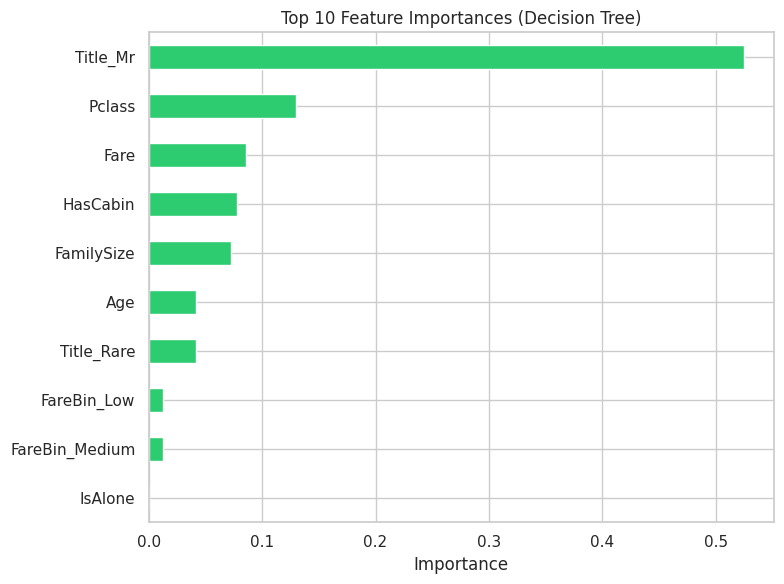

In [15]:
# Feature importance from Decision Tree
feature_imp = pd.Series(dt.feature_importances_, index=X_train.columns)
feature_imp = feature_imp.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp.tail(10).plot(kind="barh", ax=ax, color="#2ecc71")
ax.set_title("Top 10 Feature Importances (Decision Tree)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


### 3.3 Random Forest

Combines trees trained on bootstrap samples, with random feature subsets considered
at each split. Averaging their probabilities can reduce variance relative to a single tree.


In [16]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=7,
    random_state=42
)

rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(f"Training accuracy: {rf.score(X_train, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_rf):.2%}")

print(classification_report(
    y_test, y_pred_rf,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))


Training accuracy: 90.59%
Test accuracy: 81.01%
                 precision    recall  f1-score   support

Did not survive       0.83      0.87      0.85       110
       Survived       0.78      0.71      0.74        69

       accuracy                           0.81       179
      macro avg       0.80      0.79      0.80       179
   weighted avg       0.81      0.81      0.81       179



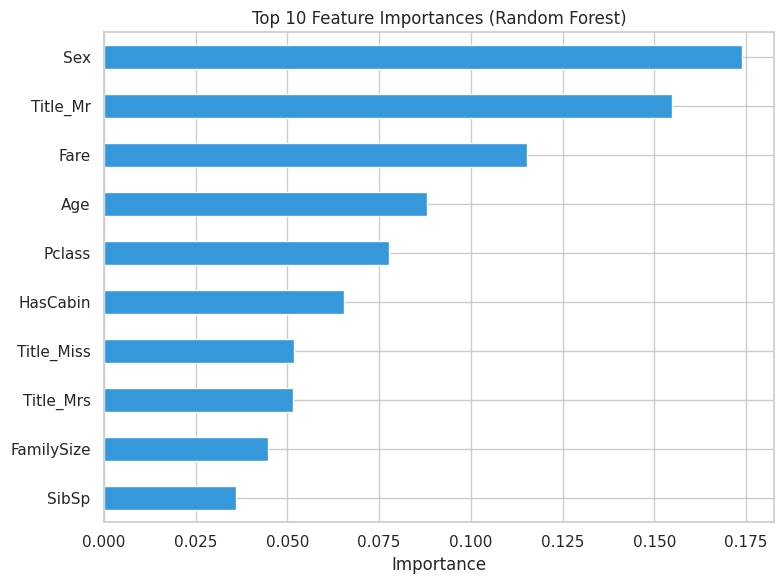

In [17]:
# Feature importance from Random Forest
feature_imp_rf = pd.Series(rf.feature_importances_, index=X_train.columns)
feature_imp_rf = feature_imp_rf.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
feature_imp_rf.tail(10).plot(kind="barh", ax=ax, color="#3498db")
ax.set_title("Top 10 Feature Importances (Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()


### 3.4 K-Nearest Neighbors (KNN)

Classifies based on the majority vote of the K closest training samples. Requires scaled features.

In [18]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)

print(f"Training accuracy: {knn.score(X_train_scaled, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_knn):.2%}")

print(classification_report(
    y_test, y_pred_knn,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))


Training accuracy: 86.24%
Test accuracy: 77.65%
                 precision    recall  f1-score   support

Did not survive       0.80      0.85      0.82       110
       Survived       0.74      0.65      0.69        69

       accuracy                           0.78       179
      macro avg       0.77      0.75      0.76       179
   weighted avg       0.77      0.78      0.77       179



### 3.5 Support Vector Machine (SVM)

A regularized margin classifier. The RBF kernel allows a nonlinear boundary in
the original feature space. Distances make feature scaling important.


In [19]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", C=1.0, gamma="scale")

svm.fit(X_train_scaled, y_train)
y_pred_svm = svm.predict(X_test_scaled)

print(f"Training accuracy: {svm.score(X_train_scaled, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_svm):.2%}")

print(classification_report(
    y_test, y_pred_svm,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))


Training accuracy: 85.67%
Test accuracy: 81.56%
                 precision    recall  f1-score   support

Did not survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179



### 3.6 Gradient Boosting

An ensemble method that builds trees sequentially, where each tree corrects the errors of the previous one.

In [20]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_test)

print(f"Training accuracy: {gb.score(X_train, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_gb):.2%}")

print(classification_report(
    y_test, y_pred_gb,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))


Training accuracy: 90.87%
Test accuracy: 81.01%
                 precision    recall  f1-score   support

Did not survive       0.81      0.90      0.85       110
       Survived       0.81      0.67      0.73        69

       accuracy                           0.81       179
      macro avg       0.81      0.78      0.79       179
   weighted avg       0.81      0.81      0.81       179



### 3.7 Gaussian Naive Bayes

Uses class priors and Gaussian feature likelihoods, assuming conditional independence
of features given the outcome. Correlated and binary features make those assumptions
imperfect for this dataset; it serves as a comparison baseline.


In [21]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_test)

print(f"Training accuracy: {nb.score(X_train, y_train):.2%}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_nb):.2%}")

print(classification_report(
    y_test, y_pred_nb,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))


Training accuracy: 78.51%
Test accuracy: 78.21%
                 precision    recall  f1-score   support

Did not survive       0.87      0.76      0.81       110
       Survived       0.68      0.81      0.74        69

       accuracy                           0.78       179
      macro avg       0.77      0.79      0.78       179
   weighted avg       0.80      0.78      0.78       179



## 4. Model Comparison

In [22]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "KNN": y_pred_knn,
    "SVM": y_pred_svm,
    "Gradient Boosting": y_pred_gb,
    "Gaussian Naive Bayes": y_pred_nb
}

rows = []

for name, predicted in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0)
    })

comparison = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("Accuracy", ascending=False)
)

display(comparison.round(4))


,Accuracy,Precision,Recall,F1
Model,,,,
Logistic Regression,0.8436,0.7971,0.7971,0.7971
SVM,0.8156,0.8000,0.6957,0.7442
Random Forest,0.8101,0.7778,0.7101,0.7424
Gradient Boosting,0.8101,0.8070,0.6667,0.7302
Decision Tree,0.8045,0.7931,0.6667,0.7244
Gaussian Naive Bayes,0.7821,0.6829,0.8116,0.7417
KNN,0.7765,0.7377,0.6522,0.6923


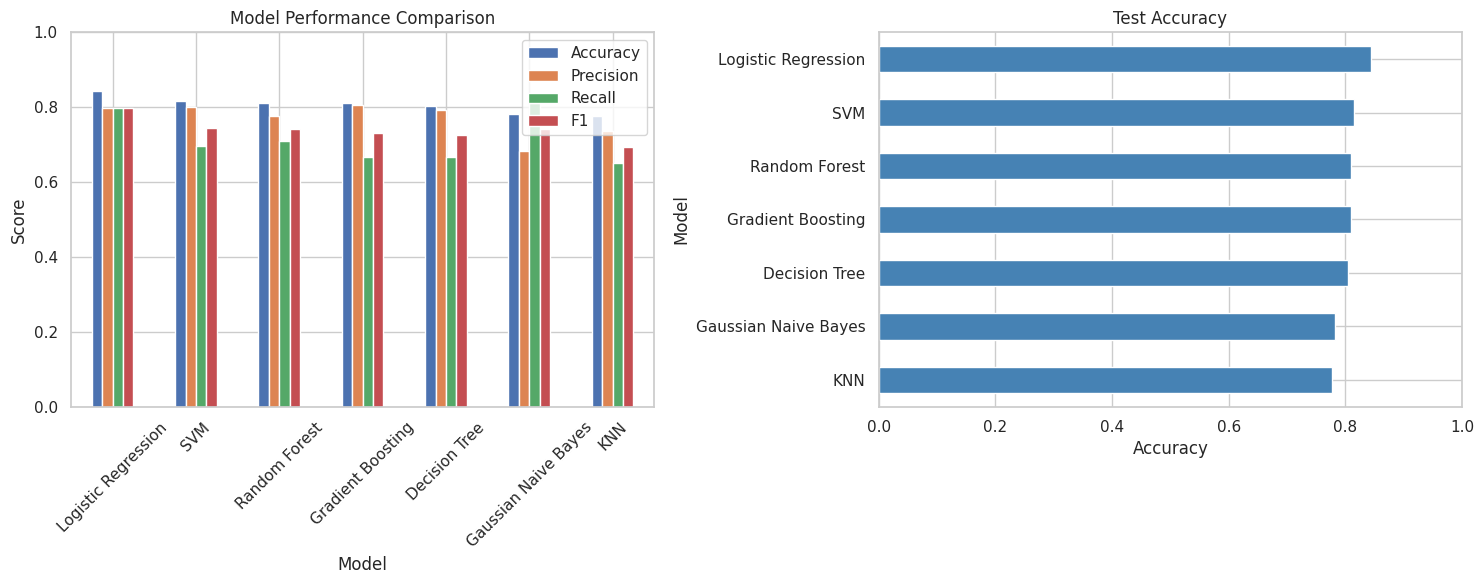

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

comparison.plot.bar(ax=axes[0])
axes[0].set_title("Model Performance Comparison")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", labelrotation=45)

comparison["Accuracy"].sort_values().plot.barh(
    ax=axes[1], color="steelblue"
)
axes[1].set_title("Test Accuracy")
axes[1].set_xlabel("Accuracy")
axes[1].set_xlim(0, 1)

plt.tight_layout()
plt.show()

## 5. Cross-Validation

Use five stratified folds of the 712 training passengers. Each fold learns its own
imputation values, fare boundaries, categories, and scaling. Test passengers are excluded.
The fold standard deviation describes score variation, not a confidence interval.


In [24]:
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Learn preprocessing using only the current fold's training passengers.
def prepare_fold(fold_train, fold_valid):
    medians = fold_train.groupby(["Pclass", "Sex"])["Age"].median()
    fallback = fold_train["Age"].median()
    port = fold_train["Embarked"].mode()[0]

    def prepare(data):
        data = data.copy()

        replacement_ages = data.apply(
            lambda row: medians.get(
                (row["Pclass"], row["Sex"]), fallback
            ),
            axis=1
        )

        data["Age"] = data["Age"].fillna(
            replacement_ages
        ).fillna(fallback)

        data["Embarked"] = data["Embarked"].fillna(port)

        data = add_family_and_cabin(data)
        data = add_title_and_age_group(data)
        return data

    train = prepare(fold_train)
    valid = prepare(fold_valid)

    _, edges = pd.qcut(train["Fare"], q=4, retbins=True)
    edges[0], edges[-1] = -np.inf, np.inf

    for data in [train, valid]:
        data["FareBin"] = pd.cut(
            data["Fare"],
            bins=edges,
            labels=["Low", "Medium", "High", "Very High"]
        )

    fold_encoder = clone(encoder)

    train_x = fold_encoder.fit_transform(select_features(train))
    valid_x = fold_encoder.transform(select_features(valid))

    return train_x, valid_x


models_for_cv = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf,
    "KNN": knn,
    "SVM": svm,
    "Gradient Boosting": gb,
    "Gaussian Naive Bayes": nb
}

scaled_models = {"Logistic Regression", "KNN", "SVM"}
cv_results = {name: [] for name in models_for_cv}

folds = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

for train_idx, valid_idx in folds.split(
    raw_train, raw_train["Survived"]
):
    fold_train = raw_train.iloc[train_idx]
    fold_valid = raw_train.iloc[valid_idx]

    train_x, valid_x = prepare_fold(fold_train, fold_valid)
    train_y = fold_train["Survived"]
    valid_y = fold_valid["Survived"]

    fold_scaler = StandardScaler()
    train_scaled = fold_scaler.fit_transform(train_x)
    valid_scaled = fold_scaler.transform(valid_x)

    for name, original_model in models_for_cv.items():
        model = clone(original_model)

        if name in scaled_models:
            model.fit(train_scaled, train_y)
            score = model.score(valid_scaled, valid_y)
        else:
            model.fit(train_x, train_y)
            score = model.score(valid_x, valid_y)

        cv_results[name].append(score)

cv_summary = pd.DataFrame({
    name: {
        "Mean CV accuracy": np.mean(scores),
        "Fold standard deviation": np.std(scores)
    }
    for name, scores in cv_results.items()
}).T.sort_values("Mean CV accuracy", ascending=False)

display(cv_summary.round(4))

,Mean CV accuracy,Fold standard deviation
Logistic Regression,0.8244,0.0285
Random Forest,0.8189,0.0310
SVM,0.8188,0.0155
Gradient Boosting,0.8174,0.0290
KNN,0.8091,0.0314
Decision Tree,0.8062,0.0218
Gaussian Naive Bayes,0.7823,0.0240


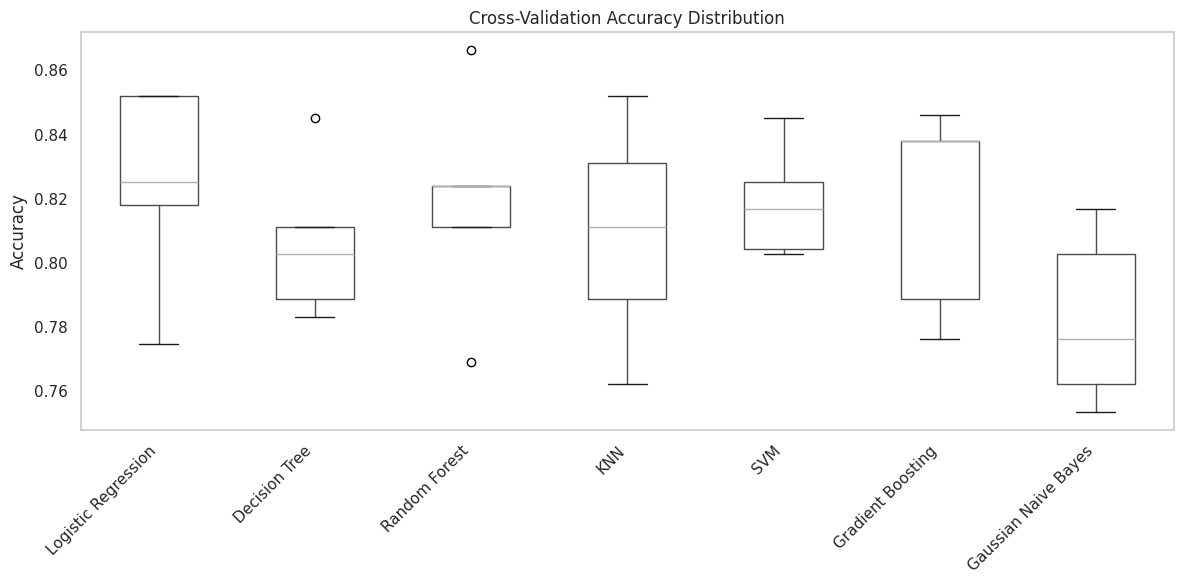

In [25]:
# Box plot of cross-validation scores
fig, ax = plt.subplots(figsize=(12, 6))
cv_df = pd.DataFrame(cv_results)
cv_df.boxplot(ax=ax, grid=False)
ax.set_title("Cross-Validation Accuracy Distribution")
ax.set_ylabel("Accuracy")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 6. ROC Curve Comparison

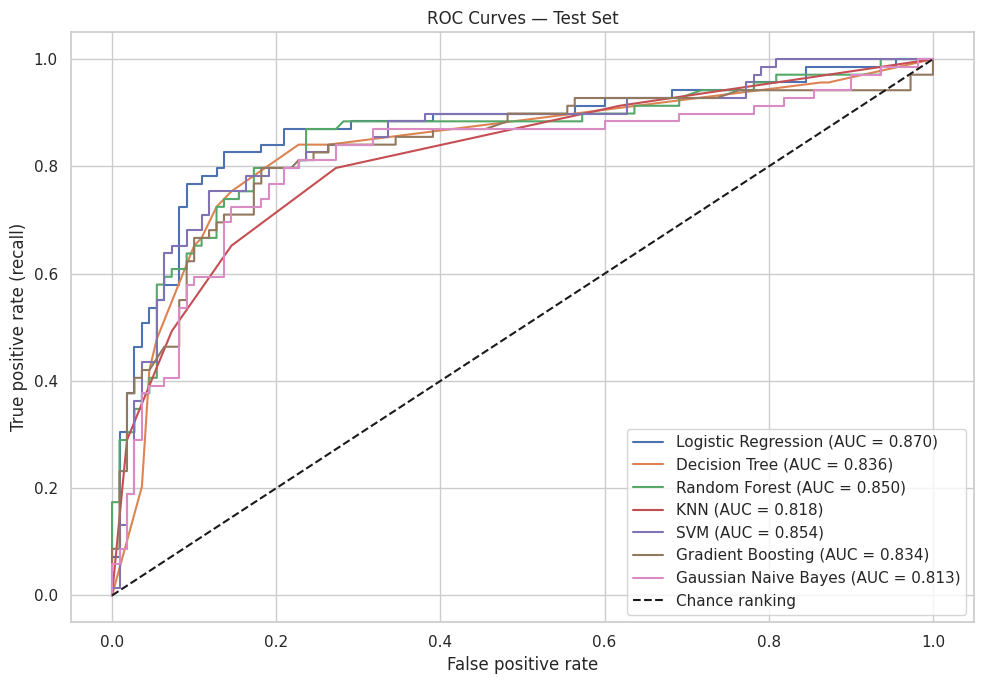

In [26]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Pair each fitted model with the inputs it was trained to use.
roc_models = {
    "Logistic Regression": (lr, X_test_scaled),
    "Decision Tree": (dt, X_test),
    "Random Forest": (rf, X_test),
    "KNN": (knn, X_test_scaled),
    "SVM": (svm, X_test_scaled),
    "Gradient Boosting": (gb, X_test),
    "Gaussian Naive Bayes": (nb, X_test)
}

auc_scores = {}
plt.figure(figsize=(10, 7))

for name, (model, inputs) in roc_models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(inputs)[:, 1]
    else:
        scores = model.decision_function(inputs)

    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_scores[name] = roc_auc_score(y_test, scores)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_scores[name]:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Chance ranking")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.title("ROC Curves — Test Set")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 7. Hyperparameter Tuning — Logistic Regression

Compare five regularization strengths using the same training-only folds and accuracy
metric. Smaller `C` gives stronger regularization. Refit the selected setting on all
training passengers. The best tuning score is not an independent performance estimate.


In [27]:
# Prepare each fold once, using our corrected preprocessing.
prepared_folds = []

for train_idx, valid_idx in folds.split(
    raw_train, raw_train["Survived"]
):
    fold_train = raw_train.iloc[train_idx]
    fold_valid = raw_train.iloc[valid_idx]

    train_x, valid_x = prepare_fold(fold_train, fold_valid)

    fold_scaler = StandardScaler()
    train_x = fold_scaler.fit_transform(train_x)
    valid_x = fold_scaler.transform(valid_x)

    prepared_folds.append((
        train_x,
        valid_x,
        fold_train["Survived"],
        fold_valid["Survived"]
    ))

tuning_rows = []

for c_value in [0.01, 0.1, 1.0, 10.0, 100.0]:
    scores = []

    for train_x, valid_x, train_y, valid_y in prepared_folds:
        candidate = LogisticRegression(
            C=c_value,
            max_iter=1000,
            random_state=42
        )
        candidate.fit(train_x, train_y)
        scores.append(candidate.score(valid_x, valid_y))

    tuning_rows.append({
        "C": c_value,
        "Mean CV accuracy": np.mean(scores),
        "Fold standard deviation": np.std(scores)
    })

tuning_table = pd.DataFrame(tuning_rows).sort_values(
    "Mean CV accuracy", ascending=False
)

display(tuning_table.round(4))

best_c = float(tuning_table.iloc[0]["C"])
print("Selected C:", best_c)

# Refit the selected setting on all training passengers.
tuned_lr = LogisticRegression(
    C=best_c,
    max_iter=1000,
    random_state=42
)
tuned_lr.fit(X_train_scaled, y_train)


Selected C: 1.0
Out[27]: LogisticRegression(max_iter=1000, random_state=42)


,C,Mean CV accuracy,Fold standard deviation
2,1.00,0.8244,0.0285
4,100.00,0.8244,0.0288
3,10.00,0.8230,0.0272
1,0.10,0.8216,0.0253
0,0.01,0.7978,0.0173


Selected Logistic Regression
C: 1.0
Test accuracy: 84.36%
                 precision    recall  f1-score   support

Did not survive       0.87      0.87      0.87       110
       Survived       0.80      0.80      0.80        69

       accuracy                           0.84       179
      macro avg       0.83      0.83      0.83       179
   weighted avg       0.84      0.84      0.84       179



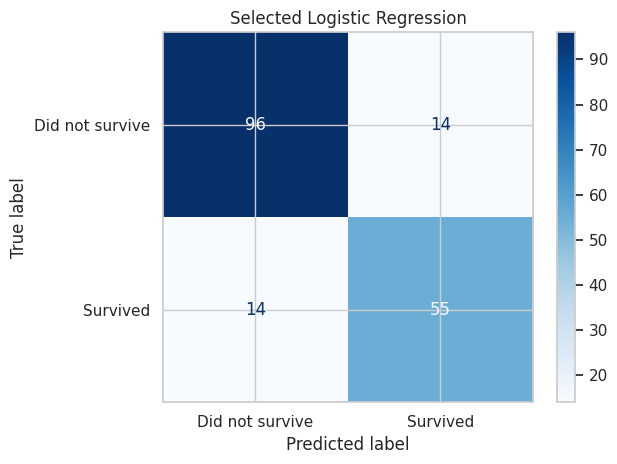

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay

y_pred_tuned = tuned_lr.predict(X_test_scaled)

print("Selected Logistic Regression")
print(f"C: {best_c}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_tuned):.2%}")

print(classification_report(
    y_test, y_pred_tuned,
    target_names=["Did not survive", "Survived"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tuned,
    labels=[0, 1],
    display_labels=["Did not survive", "Survived"],
    cmap="Blues"
)
plt.title("Selected Logistic Regression")
plt.tight_layout()
plt.show()

## 8. Feature Weights — Selected Logistic Regression

Positive coefficients increase survival log-odds and negative coefficients decrease
them, holding other inputs fixed. Inputs are standardized, so each coefficient is
per training standard deviation. Dummy coefficients relate to an omitted category;
their raw 0-to-1 effect also depends on scaling. Related and redundant features share
information, so absolute weight is not a definitive importance ranking. These are
model associations, not causal effects.


Five largest absolute coefficients:
Title_Mr     -1.203
Sex           0.773
Pclass       -0.535
Title_Miss   -0.534
SibSp        -0.401
Name: Coefficient, dtype: float64


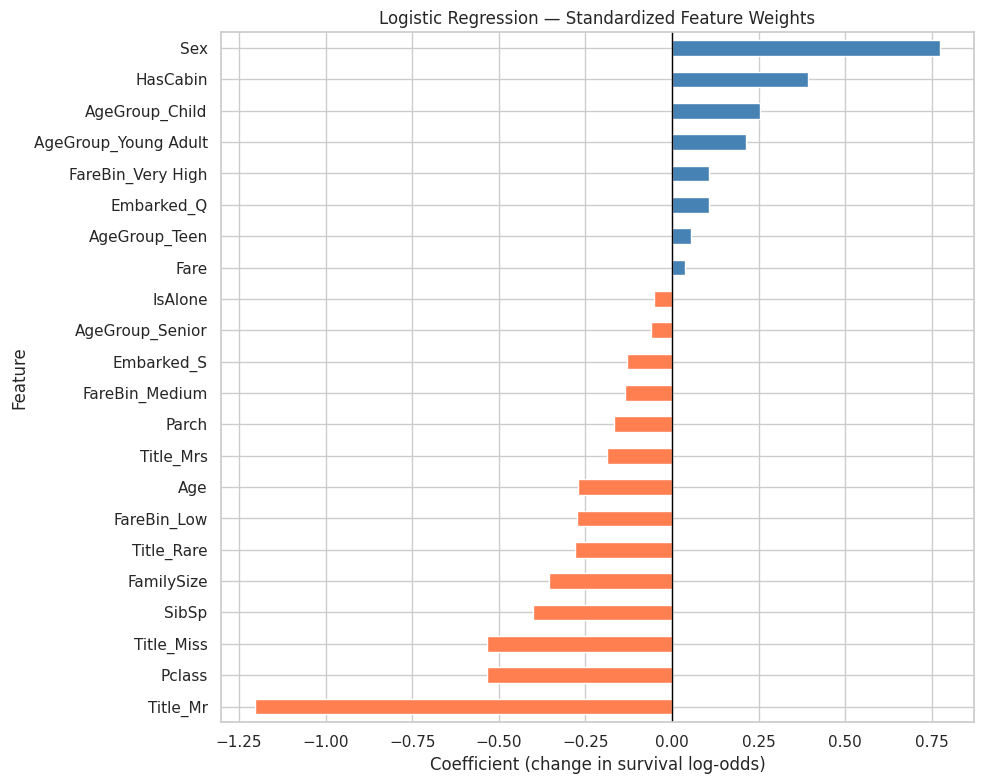

In [29]:
weights = pd.Series(
    tuned_lr.coef_[0],
    index=X_train_scaled.columns,
    name="Coefficient"
).sort_values()

colors = [
    "steelblue" if value > 0 else "coral"
    for value in weights
]

fig, ax = plt.subplots(figsize=(10, 8))

weights.plot.barh(ax=ax, color=colors)
ax.axvline(0, color="black", linewidth=1)

ax.set_title("Logistic Regression — Standardized Feature Weights")
ax.set_xlabel("Coefficient (change in survival log-odds)")
ax.set_ylabel("Feature")

plt.tight_layout()
plt.show()

print("Five largest absolute coefficients:")
largest = weights.abs().nlargest(5).index
print(weights.loc[largest].round(3))


## 9. Make Predictions on New Data

Let's see how to use the trained model to predict survival for a new passenger.

In [30]:
# A fictional passenger; no known survival outcome.
new_passenger = pd.DataFrame([{
    "PassengerId": 1000,
    "Pclass": 2,
    "Name": "Example, Mrs. Jane",
    "Sex": "female",
    "Age": 28,
    "SibSp": 1,
    "Parch": 0,
    "Ticket": "EXAMPLE",
    "Fare": 26.0,
    "Cabin": None,
    "Embarked": "S"
}])

# Apply the same rules learned from training passengers.
new_prepared = fill_missing(new_passenger)
new_prepared = add_family_and_cabin(new_prepared)
new_prepared = add_title_and_age_group(new_prepared)

new_prepared["FareBin"] = pd.cut(
    new_prepared["Fare"],
    bins=fare_edges,
    labels=["Low", "Medium", "High", "Very High"]
)

new_features = new_prepared.drop(
    columns=["PassengerId", "Name", "Ticket", "Cabin"]
).copy()

new_features["Sex"] = new_features["Sex"].map({
    "male": 0, "female": 1
})

new_encoded = pd.DataFrame(
    encoder.transform(new_features),
    columns=encoder.get_feature_names_out(),
    index=new_features.index
)

new_scaled = pd.DataFrame(
    scaler.transform(new_encoded),
    columns=new_encoded.columns,
    index=new_encoded.index
)

probability = tuned_lr.predict_proba(new_scaled)[0, 1]
prediction = tuned_lr.predict(new_scaled)[0]

print(f"Estimated survival probability: {probability:.1%}")
print(
    "Predicted outcome:",
    "Survived" if prediction == 1 else "Did not survive"
)


Estimated survival probability: 85.0%
Predicted outcome: Survived


## 10. Final Summary

### Model Performance Summary

In [31]:
final_df = comparison.copy()

final_df["ROC AUC"] = pd.Series(auc_scores)
final_df["Mean CV accuracy"] = cv_summary["Mean CV accuracy"]

display(final_df.round(4))

print("\nSelected model: Logistic Regression")
print(f"Selected C: {best_c}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred_tuned):.2%}")



Selected model: Logistic Regression
Selected C: 1.0
Test accuracy: 84.36%


,Accuracy,Precision,Recall,F1,ROC AUC,Mean CV accuracy
Model,,,,,,
Logistic Regression,0.8436,0.7971,0.7971,0.7971,0.8705,0.8244
SVM,0.8156,0.8000,0.6957,0.7442,0.8536,0.8188
Random Forest,0.8101,0.7778,0.7101,0.7424,0.8499,0.8189
Gradient Boosting,0.8101,0.8070,0.6667,0.7302,0.8342,0.8174
Decision Tree,0.8045,0.7931,0.6667,0.7244,0.8365,0.8062
Gaussian Naive Bayes,0.7821,0.6829,0.8116,0.7417,0.8134,0.7823
KNN,0.7765,0.7377,0.6522,0.6923,0.8184,0.8091


### Key Takeaways

1. Logistic regression achieved the highest test accuracy (84.36%),
   survivor F1 (0.7971), and ROC AUC (0.8705) among the seven models.

2. Logistic regression also had the highest mean five-fold
   cross-validation accuracy (82.44%), although its advantage over
   the other leading models was small.

3. More complex models did not automatically perform better.

4. Preprocessing was learned from training passengers and refitted
   separately within each cross-validation fold to prevent leakage.

5. Regularization tuning selected C = 1.0, retaining the original
   logistic regression setting without improving its results.

6. Feature weights describe associations within the fitted model,
   not causal effects. Related features complicate interpretation.

### Limitations

- The test set was inspected throughout this educational comparison;
  it was not an untouched final evaluation.
- Feature engineering was used, but its improvement was not measured
  against a model without the engineered features.
- Predicted probabilities were not assessed for calibration.
